# 04. RFM-сегментация

Разбиваем покупателей на сегменты по поведению, чтобы работать с ними по-разному: удерживать лучших, возвращать уходящих, не тратить бюджет на потерянных.

- **R (recency)** - сколько дней прошло с последней покупки;
- **F (frequency)** - сколько всего покупок;
- **M (monetary)** - сколько денег принёс клиент.

Каждой метрике ставится балл 1-5 (больше = лучше), по сочетанию R и F клиент попадает в сегмент. M в правилах сегментов не участвует - он сильно коррелирует с F и используется для описания сегментов.

**Данные:** `marts.dim_customers` - только клиенты хотя бы с одной покупкой. Логика вынесена в `analytics/rfm.py` и продублирована в dbt-витрине `marts.mart_customer_rfm` для BI; в конце ноутбука сверяем, что они совпадают.

In [1]:
import sys
sys.path.insert(0, "..")  # модуль analytics лежит в корне репозитория

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from analytics.db import query
from analytics.plots import setup, money_axis, percent_axis, BLUE, ORANGE, AQUA, YELLOW, GRAY, SERIES

setup()
pd.set_option("display.float_format", "{:,.2f}".format)

from statsmodels.stats.proportion import proportion_confint
from analytics.rfm import rfm_scores, SEGMENTS, SEGMENT_ORDER, QUANTILES, F_THRESHOLDS

In [2]:
buyers = query("""
    select
        customer_id,
        assumeNotNull(days_since_last_purchase) as recency_days,
        purchases_count as frequency,
        lifetime_revenue as monetary
    from dim_customers
    where purchases_count > 0
""")
print(f"Покупателей: {len(buyers):,}")
buyers[["recency_days", "frequency", "monetary"]].describe(percentiles=[0.2, 0.4, 0.5, 0.6, 0.8]).T

Покупателей: 5,776


,count,mean,std,min,20%,40%,50%,60%,80%,max
recency_days,"5,776.00",55.90,47.20,0.00,12.00,31.00,41.00,57.00,100.00,180.00
frequency,"5,776.00",2.43,2.40,1.00,1.00,1.00,1.00,2.00,3.00,29.00
monetary,"5,776.00","2,896.08","3,743.81",14.98,282.08,665.44,"1,489.91","2,426.66","4,980.39","44,810.26"


## Распределения и выбор правил

Все три метрики сильно скошены, поэтому фиксированные пороги «на глаз» (например, «M > 1000») дали бы группы очень разного размера и требовали бы пересмотра при росте цен. Стандартный выход - квинтили: каждая группа содержит 20% клиентов.

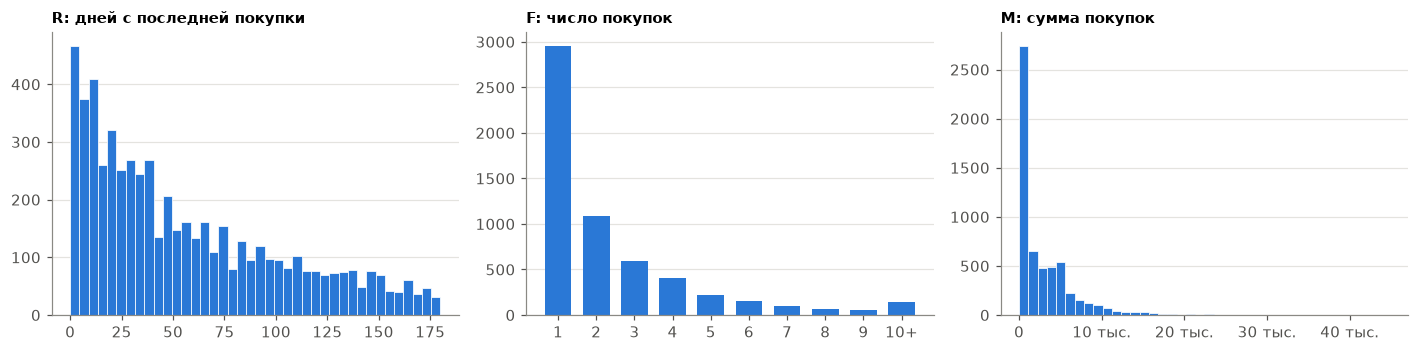

Квинтили F: [1. 1. 2. 3.]
Купили ровно один раз: 51.2%


In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].hist(buyers.recency_days, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set_title("R: дней с последней покупки", fontsize=10)
f_counts = buyers.frequency.clip(upper=10).value_counts().sort_index()
axes[1].bar(f_counts.index.astype(str).str.replace("10", "10+"), f_counts.values, color=BLUE, width=0.7)
axes[1].set_title("F: число покупок", fontsize=10)
axes[2].hist(buyers.monetary, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
axes[2].set_title("M: сумма покупок", fontsize=10)
money_axis(axes[2], axis="x")
for ax in axes:
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

print("Квинтили F:", np.quantile(buyers.frequency, QUANTILES))
print(f"Купили ровно один раз: {(buyers.frequency == 1).mean():.1%}")

Для R и M квинтили работают. Для F - нет: половина клиентов купила ровно один раз, границы квинтилей совпадают (`[1, 1, 2, 3]`), и равных групп не получается при любом способе разбиения одинаковых значений. Поэтому F режем по фиксированным порогам `1 | 2 | 3-4 | 5-7 | 8+`.

Давность в витрине считается от даты среза (день последнего заказа в данных), а не от сегодняшней даты, поэтому баллы не зависят от дня, когда собрана витрина.

In [4]:
scored = rfm_scores(buyers)

score_sizes = pd.DataFrame({k: scored[f"{k.lower()}_score"].value_counts(normalize=True).sort_index()
                            for k in ["R", "F", "M"]})
score_sizes.index.name = "балл"
score_sizes.style.format("{:.1%}")

,R,F,M
балл,,,
1,20.0%,51.2%,20.0%
2,19.6%,18.7%,20.0%
3,19.7%,17.2%,20.0%
4,20.4%,8.3%,20.0%
5,20.3%,4.5%,20.0%


## Карта R x F

Число клиентов в каждой клетке; сегменты - области этой карты (правила в `analytics/rfm.py`). Правый верхний угол - лучшие клиенты, левый нижний - потерянные.

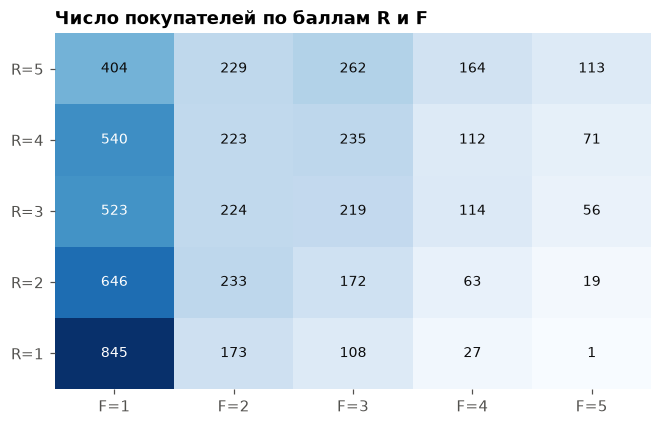

In [5]:
grid = scored.pivot_table(index="r_score", columns="f_score", values="customer_id", aggfunc="count", fill_value=0)
grid = grid.sort_index(ascending=False)

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.imshow(grid.values, cmap="Blues", aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.iat[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=9,
                color="white" if v > grid.values.max() * 0.6 else "#0b0b0b")
ax.set_xticks(range(grid.shape[1]), [f"F={c}" for c in grid.columns])
ax.set_yticks(range(grid.shape[0]), [f"R={r}" for r in grid.index])
ax.set_title("Число покупателей по баллам R и F")
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
plt.show()

## Сегменты

In [6]:
seg = scored.groupby("segment").agg(
    customers=("customer_id", "size"),
    revenue=("monetary", "sum"),
    recency=("recency_days", "median"),
    frequency=("frequency", "mean"),
    monetary=("monetary", "mean"),
).reindex(SEGMENT_ORDER)
seg["customers_share"] = seg.customers / seg.customers.sum()
seg["revenue_share"] = seg.revenue / seg.revenue.sum()
seg.insert(0, "description", dict(SEGMENTS).values())

seg.drop(columns="revenue").style.format({
    "customers": "{:,.0f}", "customers_share": "{:.1%}", "revenue_share": "{:.1%}",
    "recency": "{:.0f}", "frequency": "{:.1f}", "monetary": "{:,.0f}"})

,description,customers,recency,frequency,monetary,customers_share,revenue_share
segment,,,,,,,
Чемпионы,покупают часто и недавно,460,10,7.7,"9,249",8.0%,25.4%
Лояльные,покупают регулярно,886,26,4.2,"4,984",15.3%,26.4%
Новички,"купили недавно, но пока 1-2 раза","1,396",14,1.3,"1,588",24.2%,13.3%
Под угрозой,"покупали часто, но давно не возвращались",390,88,4.3,"4,776",6.8%,11.1%
Требуют внимания,"средняя давность, мало покупок",747,42,1.3,"1,659",12.9%,7.4%
Засыпают,давно и мало,879,76,1.3,"1,511",15.2%,7.9%
Потерянные,очень давно и мало,"1,018",134,1.2,"1,385",17.6%,8.4%


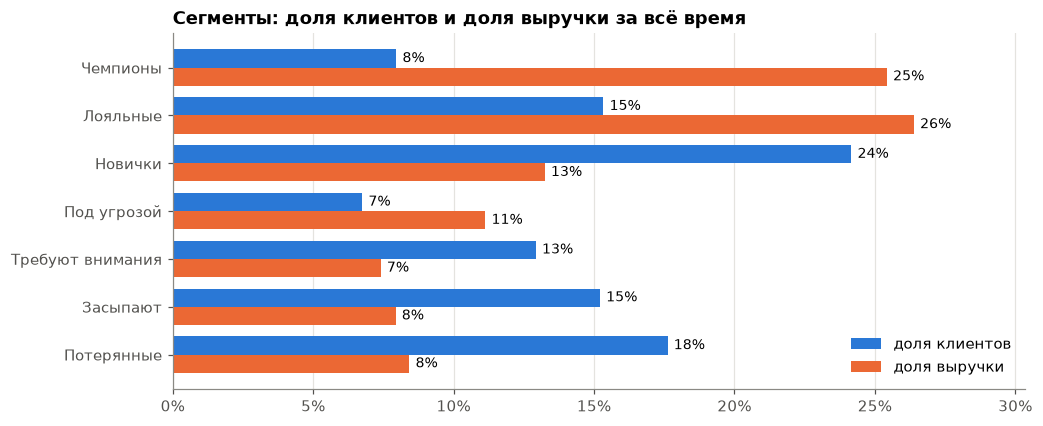

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(seg))
h = 0.38
ax.barh(y - h / 2, seg.customers_share, height=h, color=BLUE, label="доля клиентов")
ax.barh(y + h / 2, seg.revenue_share, height=h, color=ORANGE, label="доля выручки")
for i, (c, r) in enumerate(zip(seg.customers_share, seg.revenue_share)):
    ax.annotate(f"{c:.0%}", (c, i - h / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
    ax.annotate(f"{r:.0%}", (r, i + h / 2), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9)
ax.set_yticks(y, seg.index)
ax.invert_yaxis()
percent_axis(ax, axis="x")
ax.set_xlim(0, max(seg.customers_share.max(), seg.revenue_share.max()) * 1.15)
ax.set_title("Сегменты: доля клиентов и доля выручки за всё время")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

## Работают ли сегменты: бэктест

Сегментация полезна, только если предсказывает поведение. Проверка: считаем RFM на дату 60 дней назад (по покупкам до неё) и смотрим, какая доля каждого сегмента купила что-нибудь в следующие 60 дней. Если сегменты осмысленны, доли должны заметно различаться и убывать от «Чемпионов» к «Потерянным».

Оговорка: последние 42 дня из этих 60 идёт A/B-эксперимент со скидкой для половины клиентов. Он поднимает покупки в группе treatment во всех сегментах одинаково и порядок сегментов не меняет.

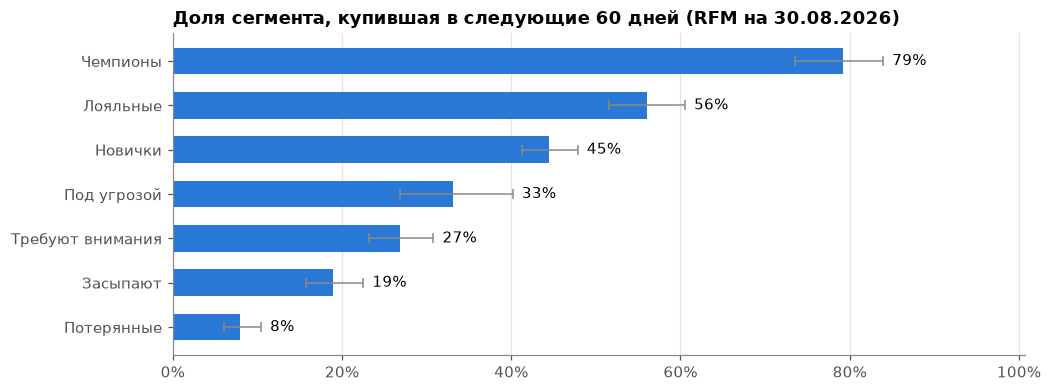

,customers,returned,rate,lo,hi,next_revenue
segment,,,,,,
Чемпионы,231,183,79.2%,73.5%,84.0%,"2,448"
Лояльные,467,262,56.1%,51.6%,60.5%,"1,584"
Новички,858,382,44.5%,41.2%,47.9%,"1,106"
Под угрозой,187,62,33.2%,26.8%,40.2%,605
Требуют внимания,525,141,26.9%,23.2%,30.8%,549
Засыпают,518,98,18.9%,15.8%,22.5%,294
Потерянные,612,49,8.0%,6.1%,10.4%,147


In [8]:
purchases = query("select customer_id, order_date, order_total from fct_orders where is_revenue")
HORIZON = 60
data_end = purchases.order_date.max()
cutoff = data_end - pd.Timedelta(days=HORIZON)

before = purchases[purchases.order_date <= cutoff]
history = before.groupby("customer_id").agg(last=("order_date", "max"),
                                            frequency=("order_date", "size"),
                                            monetary=("order_total", "sum"))
history["recency_days"] = (cutoff - history["last"]).dt.days
then = rfm_scores(history.reset_index())

after = (purchases[purchases.order_date > cutoff]
         .groupby("customer_id").agg(next_purchases=("order_date", "size"), next_revenue=("order_total", "sum")))
bt = then.merge(after, on="customer_id", how="left").fillna({"next_purchases": 0, "next_revenue": 0})
bt["returned"] = bt.next_purchases > 0

result = bt.groupby("segment").agg(customers=("returned", "size"), returned=("returned", "sum"),
                                   next_revenue=("next_revenue", "mean")).reindex(SEGMENT_ORDER)
result["rate"] = result.returned / result.customers
result["lo"], result["hi"] = proportion_confint(result.returned, result.customers, method="wilson")

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(result.index, result.rate, xerr=[result.rate - result.lo, result.hi - result.rate], color=BLUE,
        height=0.6, error_kw={"ecolor": GRAY, "capsize": 3, "linewidth": 1})
for i, v in enumerate(result.rate):
    ax.annotate(f"{v:.0%}", (result.hi.iloc[i], i), xytext=(6, 0), textcoords="offset points", va="center")
ax.invert_yaxis()
percent_axis(ax, axis="x")
ax.set_xlim(0, result.hi.max() * 1.2)
ax.set_title(f"Доля сегмента, купившая в следующие {HORIZON} дней (RFM на {cutoff:%d.%m.%Y})")
ax.grid(axis="y", visible=False)
plt.show()
result[["customers", "returned", "rate", "lo", "hi", "next_revenue"]].style.format(
    {"customers": "{:,.0f}", "returned": "{:,.0f}", "rate": "{:.1%}", "lo": "{:.1%}", "hi": "{:.1%}",
     "next_revenue": "{:,.0f}"})

## Сверка с dbt-витриной

Та же логика работает в `marts.mart_customer_rfm` (SQL) - оттуда сегменты возьмёт BI. Две реализации одного правила - риск расхождения, поэтому сравниваем баллы и сегменты поклиентно.

In [9]:
mart = query("select customer_id, r_score, f_score, m_score, segment from mart_customer_rfm")
cols = ["r_score", "f_score", "m_score", "segment"]
cmp = scored.merge(mart, on="customer_id", suffixes=("_py", "_dbt"), how="outer", indicator=True)

print(f"Клиентов: в ноутбуке {len(scored):,}, в витрине {len(mart):,}, в обоих {(cmp._merge == 'both').sum():,}")
for c in cols:
    print(f"{c:<8} совпадает у {(cmp[f'{c}_py'] == cmp[f'{c}_dbt']).mean():.2%} клиентов")

Клиентов: в ноутбуке 5,776, в витрине 5,776, в обоих 5,776
r_score  совпадает у 100.00% клиентов
f_score  совпадает у 100.00% клиентов
m_score  совпадает у 100.00% клиентов
segment  совпадает у 100.00% клиентов


## Что делать с сегментами

| Сегмент | Цель | Действие |
|---|---|---|
| Чемпионы | удержать, не «перекормить» скидками | ранний доступ к новинкам, программа лояльности без скидок: они покупают и так |
| Лояльные | перевести в чемпионы | персональные подборки, кросс-продажи из соседних категорий |
| Новички | получить вторую покупку | приветственная цепочка в первые 2 недели (медиана времени до второй покупки - 11 дней, ноутбук 03) |
| Под угрозой | вернуть, пока не ушли | реактивация с персональным предложением; самый ценный сегмент для скидки - потерять их дорого |
| Требуют внимания | не дать заснуть | напоминание о брошенных интересах, контент, недорогой стимул |
| Засыпают | дешёвая реактивация | массовая рассылка, без дорогих скидок |
| Потерянные | не тратить бюджет | только автоматические касания; оценить, можно ли вернуть хоть кого-то |

Эффект любого действия нужно проверять экспериментом, а не сравнением «до/после» - пример в ноутбуке 05.

## Выводы

*Данные синтетические (`backfill.py`, seed 42): цифры описывают модель магазина, а ценность ноутбука - в методике.*

1. **Правила.** 5 776 покупателей. R и M размечены квинтилями. F квинтилями разметить нельзя: 51.2% клиентов купили ровно один раз, и границы совпадают (`[1, 1, 2, 3]`). Поэтому для F используются пороги `1 | 2 | 3-4 | 5-7 | 8+`.
2. **Выручка сконцентрирована.** «Чемпионы» и «Лояльные» - это 23% клиентов и 52% выручки за всё время. Удержание этих 1 346 человек важнее любой акции на широкую базу.
3. **Главный приоритет реактивации - «Под угрозой»:** 6.8% клиентов, 11% выручки, в среднем 4 776 на клиента (в 3.4 раза больше «Потерянных»), но медиана 88 дней без покупки. Их потеря стоит дороже всего, и именно на них оправдана персональная скидка.
4. **«Новички» - крупнейший сегмент (24%).** Это следствие роста магазина. Конверсия новичка во вторую покупку - главный рычаг (см. ноутбук 03: медиана до второй покупки 11 дней).
5. **Сегменты предсказывают поведение.** В бэктесте (RFM на 30.08, горизонт 60 дней) доля купивших монотонно падает: 79% у «Чемпионов», 56% у «Лояльных», 45% у «Новичков» и 8% у «Потерянных». Доверительные интервалы крайних сегментов далеко не пересекаются. «Под угрозой» (33%) и «Требуют внимания» (27%) статистически не различаются по вероятности возврата (интервалы пересекаются, p = 0.10) - их различает ценность клиента (M), а значит, и допустимая стоимость реактивации.
6. **Две реализации совпадают.** Баллы и сегменты из `analytics/rfm.py` и из dbt-витрины `marts.mart_customer_rfm` совпадают у 100% клиентов. Квантили в обеих считаются с линейной интерполяцией: `np.quantile` и `quantilesExactInclusive` в ClickHouse.

**Ограничения и что дальше.** Правила сегментов экспертные. Альтернативы - кластеризация (k-means на логарифмах R, F, M) или вероятностные модели вроде BG/NBD, которые прогнозируют число будущих покупок и CLV по каждому клиенту, а не по сегменту.